# 23 · FTW probability cubes: maps, SQL and 3D

**Time:** 40 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** query a real FTW Zarr extract; quantify threshold sensitivity; interpret 3D probability views.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=23_ftw_probability_sql.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Carry one class from Zarr into SQL

The lab cube keeps the **field-interior** class for both years. The three-class NPZ from lesson 22 remains
available for comparisons. We copy native probability values without resampling. Rows run north to south,
columns west to east; coordinates are pixel centers. The display shows the pixel footprints.

Python uses SQLite in this notebook. The linked JavaScript lab uses **Zarrita → Arrow → DuckDB-WASM → deck.gl**,
following the zarr-sql-views approach. Neither path needs a server-side database.

2024 16384 pixels; mean: 0.826 range: 0.0 1.0
2025 16384 pixels; mean: 0.8396 range: 0.0 1.0


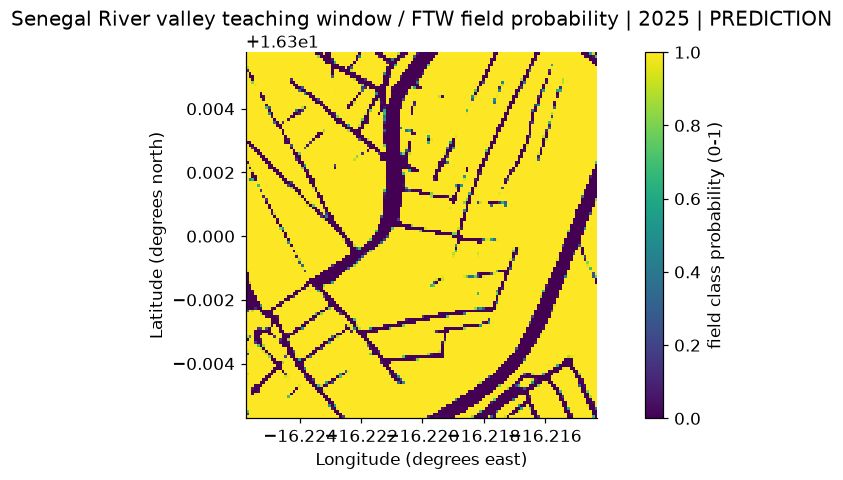

In [2]:
from ftw import load_ftw, raster_map
d=load_ftw('senegal')
meta,value=load_cube('ftw_'+d['region']['id'])
np.testing.assert_array_equal(value,d['probability'][:,1])
con=sql_connection(meta,value)
summary=list(con.execute('SELECT t, COUNT(value), AVG(value), MIN(value), MAX(value) FROM cells GROUP BY t ORDER BY t'))
for t,n,mean,low,high in summary:
    print(meta['times'][t],n,'pixels; mean:',round(mean,4),'range:',round(low,4),round(high,4))
map_slice(meta,value,1);plt.show()

## 2. A threshold changes the question

Counting pixels with `value > 0.5` asks how many pixel centers pass that model-score cutoff.
It does not count fields. A pixel fraction on this small geographic grid is also not a geodesic crop-area estimate.
Boundary pixels, excluded missing values, partial fields and model error all affect interpretation.

**Predict:** should raising the threshold ever increase the selected count? Check both SQL and NumPy.

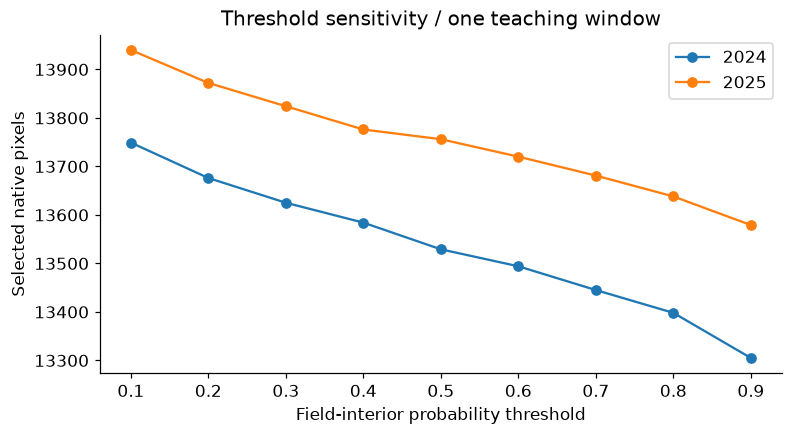

In [3]:
thresholds=np.linspace(.1,.9,9)
fig,ax=plt.subplots(figsize=(8,4))
for t,year in enumerate(d['years']):
    counts=[]
    for threshold in thresholds:
        n=con.execute('SELECT COUNT(*) FROM cells WHERE t=? AND value>?',(t,float(threshold))).fetchone()[0]
        assert n==int(np.count_nonzero(value[t]>threshold))
        counts.append(n)
    assert np.all(np.diff(counts)<=0)
    ax.plot(thresholds,counts,marker='o',label=str(year))
ax.set(xlabel='Field-interior probability threshold',ylabel='Selected native pixels',title='Threshold sensitivity / one teaching window')
ax.legend();plt.show()

## 3. Give height an honest meaning

In this surface plot, height is a probability. It is not terrain, crop height, flood depth, or agricultural output.
We show every fourth pixel to keep the 3D figure legible; this is display subsampling, not a new analytical grid.
Read the 2D map beside it: perspective and occlusion can hide detail.

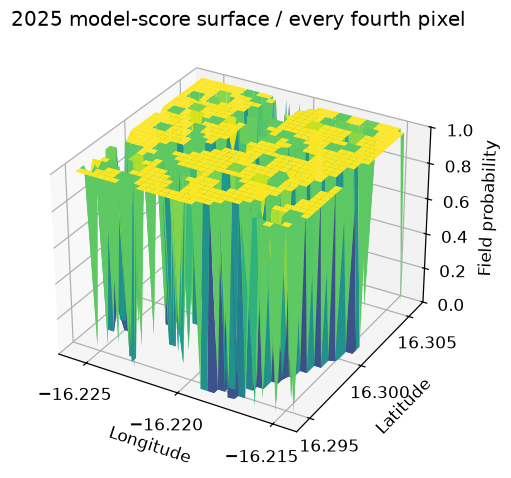

In [4]:
from matplotlib.ticker import MaxNLocator
fig=plt.figure(figsize=(10,5));ax=fig.add_subplot(111,projection='3d')
xx,yy=np.meshgrid(d['lon'][::4],d['lat'][::4])
ax.plot_surface(xx,yy,value[1,::4,::4],cmap='viridis',vmin=0,vmax=1,linewidth=0)
ax.set(xlabel='Longitude',ylabel='Latitude',zlabel='Field probability',zlim=(0,1),title='2025 model-score surface / every fourth pixel')
ax.xaxis.set_major_locator(MaxNLocator(3));ax.yaxis.set_major_locator(MaxNLocator(3))
ax.ticklabel_format(useOffset=False,style='plain',axis='both')
plt.show()

In [5]:
lab('ftw_'+d['region']['id'],'cube')

## 4. Experiment in the linked lab

Use `value > 0.5 AND t = 1` for 2025, then remove `t = 1` to compare both years.
Switch between the 2D map, 3D columns, scene and time cube. The time cube separates the two annual snapshots;
it does not show crop growth between them. Click a cell for its two-point series.

Exported lab GeoJSON contains **pixel-center points**. Lesson 24 exports **field polygons**.
Both carry attribution and provenance, but they answer different questions.

In [6]:
n=export_geojson(meta,value,'ftw-probability-points.geojson',.8)
print('Exported pixel-year points at probability >= 0.8:',n)

Exported pixel-year points at probability >= 0.8: 27036


## Try it yourself

Switch to Kenya. Run a 2025 threshold of 0.7, compare SQL with NumPy, and explain why the number of selected pixels is not the number of farms.

## Check your reasoning

A cutoff selects model scores on a grid. Polygonization, field validation and a definition of farm would each add information that the count does not contain.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Global Fields of the World on Source Cooperative](https://source.coop/ftw/global-data), Taylor Geospatial and collaborators, CC-BY-4.0.
- [Robinson et al. (2026), The first global agricultural field boundary map at 10 m resolution](https://doi.org/10.48550/arXiv.2605.11055).
- [Pinned official FTW catalog and product documentation](https://github.com/fieldsoftheworld/ftw-data-catalog/tree/fd844c4c646af0f8e653fba774f79cc17b2af124/catalog). PRUE model predictions use Copernicus Sentinel-2 composites.
- [Exact extracts, source ETags, spatial selection and SHA256 checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ftw-provenance.json). Local modifications: spatial subsets, GeoJSON conversion and scalar Zarr repackaging; original class values and full selected polygon geometries retained.
- [zarr-sql-views by dzole0311](https://github.com/dzole0311/zarr-sql-views), ISC; inspiration for the browser Zarr/SQL/graphics architecture.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [7]:
print('LESSON COMPLETE: 23_ftw_probability_sql')

LESSON COMPLETE: 23_ftw_probability_sql
